# Scene Recognition with a Convolutional Neural Network (CNN)

## What is this project?

Given a photo of a natural or urban scene, the model classifies it into one of **6 categories**: buildings, forest, glacier, mountain, sea, or street. This is **scene recognition** — a core computer vision task used in autonomous navigation, photo organization, and surveillance systems.

## Why a CNN?

Regular machine learning (logistic regression, random forests) works on **tables of numbers**. But an image is a **grid of pixels**, and what matters is *spatial patterns*: textures, shapes, edges, and how they combine. A Convolutional Neural Network is purpose-built for this:

- **Convolutional layers** scan the image with small filters, detecting patterns like "water texture" or "tree canopy"
- **Pooling layers** shrink the image, making the model focus on *what* patterns exist rather than *exactly where*
- **Dense layers** combine everything into a final classification

This is **deep learning** — multiple stacked layers that each learn increasingly abstract visual features.

## Dataset

**Intel Image Classification** — ~25,000 real-world photographs (150×150 pixels) across 6 categories.

Download from Kaggle: https://www.kaggle.com/datasets/puneet6060/intel-image-classification

After downloading and extracting, your folder structure should look like:
```
intel-image/
├── seg_train/seg_train/     (training images in 6 subfolders)
│   ├── buildings/
│   ├── forest/
│   ├── glacier/
│   ├── mountain/
│   ├── sea/
│   └── street/
├── seg_test/seg_test/       (test images in 6 subfolders)
└── seg_pred/seg_pred/       (prediction images — we won't use these)
```

---

## Step 1: Import Libraries

We need:
- **TensorFlow/Keras** — to build and train the CNN
- **OpenCV (cv2)** — to load and resize images
- **sklearn** — for evaluation metrics (confusion matrix, classification report)
- The usual pandas, numpy, matplotlib

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import os

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Step 2: Load and Preprocess the Images

### What happens here

The images are stored in folders where **the folder name IS the label** — all forest photos are in `forest/`, all sea photos are in `sea/`, etc. We:

1. Walk through each class folder
2. Read each image with OpenCV
3. **Resize to 100×100 pixels** — the originals are 150×150, but slightly smaller trains faster with minimal quality loss
4. **Convert BGR → RGB** — OpenCV loads images in BGR (blue-green-red) order, but we need standard RGB

### Why resize?

All images must be the **same size** for a CNN. Also, smaller images mean faster training: 100×100 is a good balance between detail and speed.

**Adjust `DATA_DIR` below to point to where you extracted the Kaggle download.**

In [3]:
# === CONFIGURE THIS PATH ===
DATA_DIR = "."    # adjust to your extracted folder name

IMG_SIZE = 100
CLASS_NAMES = ["buildings", "forest", "glacier", "mountain", "sea", "street"]
NUM_CLASSES = len(CLASS_NAMES)

def load_images(base_path):
    """Load images from class subfolders. Returns numpy arrays."""
    images, labels = [], []
    for label_idx, class_name in enumerate(CLASS_NAMES):
        class_dir = os.path.join(base_path, class_name)
        if not os.path.exists(class_dir):
            print(f"  WARNING: {class_dir} not found, skipping")
            continue
        files = os.listdir(class_dir)
        for fname in files:
            fpath = os.path.join(class_dir, fname)
            img = cv2.imread(fpath)
            if img is not None:
                img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                images.append(img)
                labels.append(label_idx)
    return np.array(images), np.array(labels)

# The Intel dataset has a double-nested folder: seg_train/seg_train/
# Try both patterns to find the right path
for pattern in [
    os.path.join(DATA_DIR, "seg_train", "seg_train"),
    os.path.join(DATA_DIR, "seg_train"),
    DATA_DIR
]:
    if os.path.exists(pattern) and any(
        os.path.isdir(os.path.join(pattern, c)) for c in CLASS_NAMES
    ):
        TRAIN_DIR = pattern
        break
else:
    raise FileNotFoundError("Could not find training class folders. Check DATA_DIR.")

for pattern in [
    os.path.join(DATA_DIR, "seg_test", "seg_test"),
    os.path.join(DATA_DIR, "seg_test"),
]:
    if os.path.exists(pattern) and any(
        os.path.isdir(os.path.join(pattern, c)) for c in CLASS_NAMES
    ):
        TEST_DIR = pattern
        break
else:
    raise FileNotFoundError("Could not find test class folders. Check DATA_DIR.")

print(f"Train directory: {TRAIN_DIR}")
print(f"Test directory:  {TEST_DIR}")

print("\nLoading training images...")
X_train, y_train = load_images(TRAIN_DIR)
print(f"Training: {X_train.shape[0]} images, shape {X_train.shape[1:]}")

print("Loading test images...")
X_test, y_test = load_images(TEST_DIR)
print(f"Test: {X_test.shape[0]} images")

Train directory: .\seg_train\seg_train
Test directory:  .\seg_test\seg_test

Loading training images...
Training: 14034 images, shape (100, 100, 3)
Loading test images...
Test: 3000 images


## Step 3: Normalize and One-Hot Encode

### Normalization: pixel values 0–255 → 0.0–1.0

Every pixel is an integer from 0 (black) to 255 (brightest). Dividing by 255 scales everything to the 0–1 range. Why? Neural networks train much more reliably when inputs are small numbers — large values cause unstable gradients.

### One-hot encoding the labels

The output layer uses **softmax** (outputs a probability for each class). So we convert the label number to a vector: class 2 (glacier) → `[0, 0, 1, 0, 0, 0]`.

In [4]:
# Normalize
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# One-hot encode
y_train_cat = to_categorical(y_train, NUM_CLASSES)
y_test_cat = to_categorical(y_test, NUM_CLASSES)

print(f"Pixel range: {X_train.min():.1f} to {X_train.max():.1f}")
print(f"Label shape: {y_train_cat.shape}")

Pixel range: 0.0 to 1.0
Label shape: (14034, 6)


## Step 4: Visualize the Data

Always look at your data before building a model. Two things to check:
1. **Do the images look right?** (correct labels, reasonable quality)
2. **Is the class distribution balanced?** (imbalanced data needs special handling)

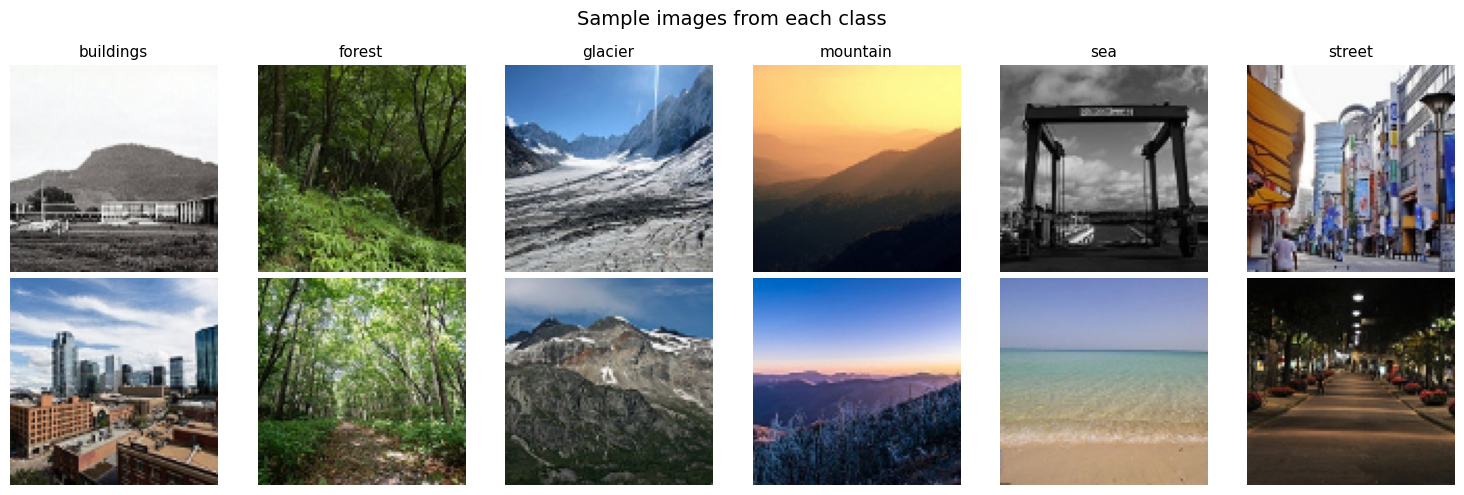

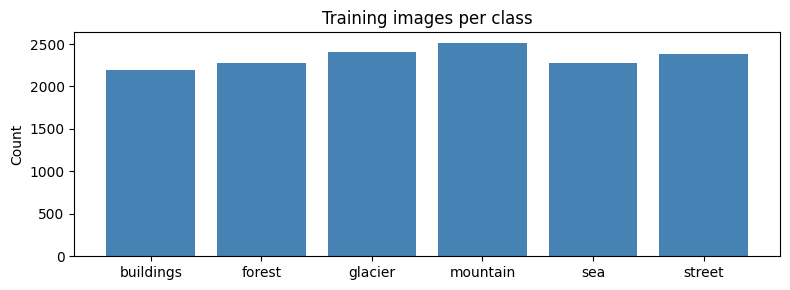

Images per class: {'buildings': np.int64(2191), 'forest': np.int64(2271), 'glacier': np.int64(2404), 'mountain': np.int64(2512), 'sea': np.int64(2274), 'street': np.int64(2382)}


In [5]:
# Show 2 examples from each class
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for col, class_name in enumerate(CLASS_NAMES):
    idxs = np.where(y_train == col)[0][:2]
    for row in range(2):
        axes[row, col].imshow(X_train[idxs[row]])
        axes[row, col].axis("off")
    axes[0, col].set_title(class_name, fontsize=11)
plt.suptitle("Sample images from each class", fontsize=14)
plt.tight_layout()
plt.show()

# Class distribution
counts = np.bincount(y_train)
plt.figure(figsize=(8, 3))
plt.bar(CLASS_NAMES, counts, color="steelblue")
plt.ylabel("Count"); plt.title("Training images per class")
plt.tight_layout(); plt.show()
print("Images per class:", dict(zip(CLASS_NAMES, counts)))

## Step 5: Data Augmentation

### Why augment?

Real-world scenes can be photographed from different angles, distances, and lighting conditions. Data augmentation creates **modified copies** of training images on-the-fly, making the model robust to these variations:

- **Rotation (±20°)** — scenes aren't always level
- **Shift (15%)** — the subject isn't always centered
- **Zoom (20%)** — varying distances
- **Horizontal flip** — a forest flipped is still a forest (unlike traffic signs, flipping scenes is safe!)

Augmentation is only applied during **training** — the test set stays untouched so it represents real conditions.

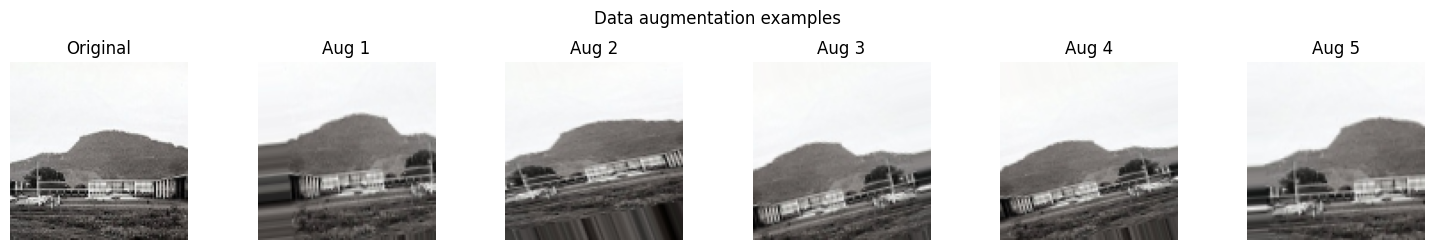

In [6]:
train_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,       # safe for scenes (unlike traffic signs!)
    fill_mode="nearest",
)
train_datagen.fit(X_train)

# Visualize augmentation on one image
fig, axes = plt.subplots(1, 6, figsize=(15, 2.5))
axes[0].imshow(X_train[0]); axes[0].set_title("Original")
for i, ax in enumerate(axes[1:]):
    aug_img = train_datagen.random_transform(X_train[0])
    ax.imshow(aug_img); ax.set_title(f"Aug {i+1}")
for ax in axes: ax.axis("off")
plt.suptitle("Data augmentation examples")
plt.tight_layout(); plt.show()

## Step 6: Build the CNN

### Layer-by-layer explanation

The CNN has **3 convolutional blocks**, each progressively detecting more complex patterns:

**Block 1 (32 filters):** detects simple patterns — edges, color gradients, basic textures. The 32 filters each learn a different low-level feature. "Is there a horizontal edge here?" "Is there a blue-to-white transition?"

**Block 2 (64 filters):** combines Block 1's outputs into medium-level patterns — "tree canopy texture," "wave pattern," "building corners." More filters because there are more possible combinations.

**Block 3 (128 filters):** highest-level patterns — "mountain ridge against sky," "urban street perspective," "ice formation." These are class-specific visual concepts.

**Each block has:**
- `Conv2D` — the pattern-detecting filter
- `BatchNormalization` — keeps training stable
- `MaxPooling2D` — shrinks spatially, focuses on strongest signals
- `Dropout (25%)` — prevents overfitting

**Classification head:**
- `Flatten` — converts 2D feature maps to a 1D vector
- `Dense(256)` — combines all features
- `Dropout(50%)` — strong regularization before final output
- `Dense(6, softmax)` — outputs probability for each scene type

In [7]:
model = models.Sequential([
    # --- Block 1: simple patterns (edges, textures) ---
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # --- Block 2: medium patterns (shapes, structures) ---
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # --- Block 3: complex patterns (scene-level features) ---
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # --- Classification head ---
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 98, 98, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 47, 47, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 21, 21, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,277,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,373,766 (12.87 MB)

 Trainable params: 3,372,806 (12.87 MB)

 Non-trainable params: 960 (3.75 KB)

## Step 7: Train the Model

### What happens during training

Each **epoch** = one full pass through all training images (augmented on-the-fly). Per batch:
1. Feed augmented images through the network (forward pass)
2. Compute **categorical cross-entropy loss** — how wrong the predictions are
3. **Backpropagation** computes gradients — which weights to adjust and by how much
4. **Adam optimizer** updates the weights

We monitor `val_accuracy` each epoch — this is the *real* performance metric since it's measured on data the model has never trained on.

**Training time:** ~10-15 minutes on your Core Ultra 5 CPU.

In [8]:
EPOCHS = 15
BATCH_SIZE = 64

history = model.fit(
    train_datagen.flow(X_train, y_train_cat, batch_size=BATCH_SIZE),
    epochs=EPOCHS,
    validation_data=(X_test, y_test_cat),
    steps_per_epoch=len(X_train) // BATCH_SIZE,
    verbose=1,
)

Epoch 1/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 134s 602ms/step - accuracy: 0.5817 - loss: 1.2035 - val_accuracy: 0.1703 - val_loss: 3.4034
Epoch 2/15
  1/219 ━━━━━━━━━━━━━━━━━━━━ 1:44 478ms/step - accuracy: 0.5469 - loss: 1.4131

C:\Users\prava\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


219/219 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.5469 - loss: 1.4131 - val_accuracy: 0.1703 - val_loss: 3.3035
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 124s 566ms/step - accuracy: 0.6818 - loss: 0.8849 - val_accuracy: 0.2827 - val_loss: 3.2237
Epoch 4/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.7188 - loss: 0.6815 - val_accuracy: 0.2967 - val_loss: 3.0191
Epoch 5/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 115s 523ms/step - accuracy: 0.7088 - loss: 0.7915 - val_accuracy: 0.7440 - val_loss: 0.7375
Epoch 6/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.7031 - loss: 0.6848 - val_accuracy: 0.7380 - val_loss: 0.7447
Epoch 7/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 100s 458ms/step - accuracy: 0.7435 - loss: 0.7074 - val_accuracy: 0.5013 - val_loss: 1.8293
Epoch 8/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.6875 - loss: 0.6805 - val_accuracy: 0.5053 - val_loss: 1.8012
Epoch 9/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 96s 438ms/step - accuracy: 0.7577 - loss: 0.6571 - val_accu

## Step 8: Training Curves

### Reading the curves

**Accuracy (left):** training accuracy should rise steadily. Validation accuracy follows but may plateau — the gap between them shows overfitting.

**Loss (right):** both should decrease. If training loss keeps falling but validation loss starts rising, the model is memorizing training data instead of learning general patterns.

A small gap is normal and healthy. A large gap means we need more augmentation, more dropout, or fewer epochs.

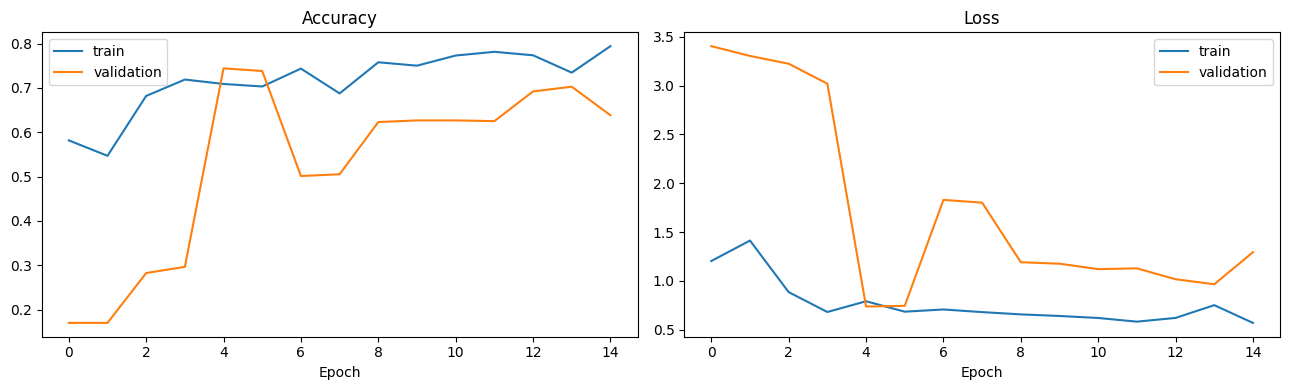

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="validation")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="validation")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()

plt.tight_layout(); plt.show()

## Step 9: Evaluate on Test Set

In [10]:
test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss:     {test_loss:.4f}")

Test Accuracy: 0.6383
Test Loss:     1.2934


## Step 10: Confusion Matrix & Per-Class Report

### Why look beyond overall accuracy?

Overall accuracy hides class-specific problems. The confusion matrix shows *which scenes get confused with each other* — for example, glaciers and mountains might look similar to the model. The classification report gives precision/recall/F1 per class.

In [11]:
y_pred_proba = model.predict(X_test)
y_pred = np.argmax(y_pred_proba, axis=1)

print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step
              precision    recall  f1-score   support

   buildings      0.415     0.911     0.571       437
      forest      0.691     0.983     0.812       474
     glacier      0.807     0.394     0.530       553
    mountain      0.818     0.505     0.624       525
         sea      0.667     0.788     0.722       510
      street      0.971     0.331     0.494       501

    accuracy                          0.638      3000
   macro avg      0.728     0.652     0.625      3000
weighted avg      0.737     0.638     0.624      3000



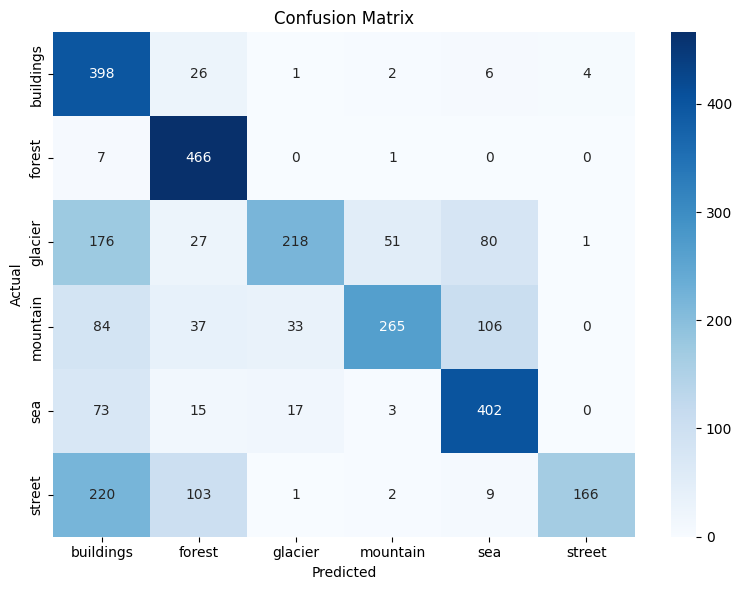

In [12]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout(); plt.show()

## Step 11: Visualize Predictions

The most intuitive check — look at real images with the model's prediction. Green = correct, Red = wrong.

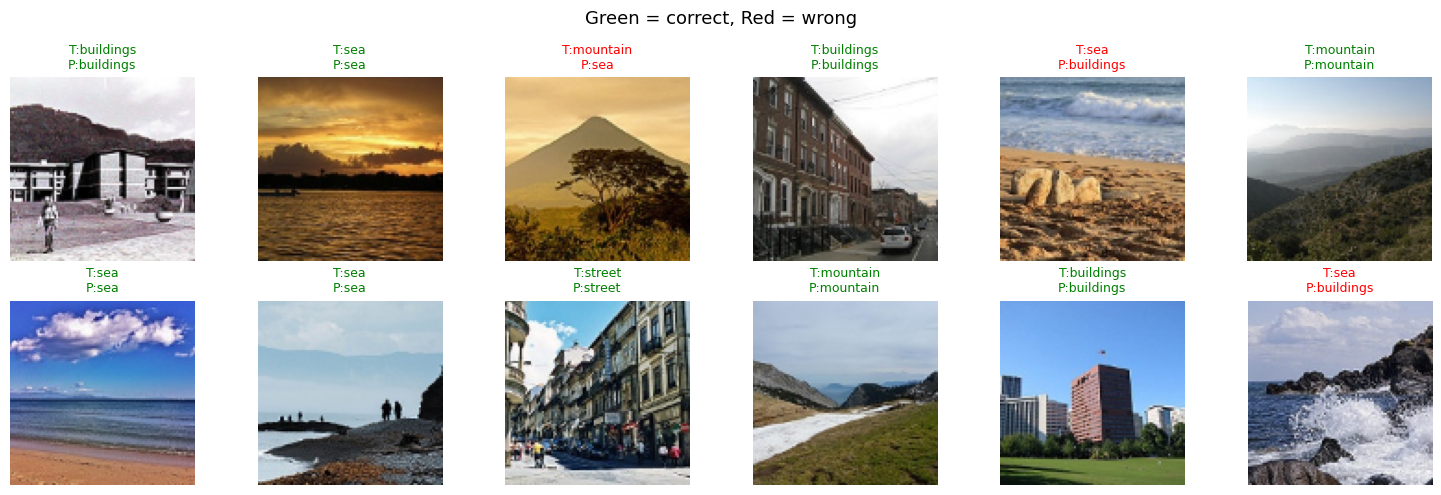

In [13]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
indices = np.random.choice(len(X_test), 12, replace=False)
for ax, idx in zip(axes.flat, indices):
    ax.imshow(X_test[idx])
    true_label = CLASS_NAMES[y_test[idx]]
    pred_label = CLASS_NAMES[y_pred[idx]]
    color = "green" if true_label == pred_label else "red"
    ax.set_title(f"T:{true_label}\nP:{pred_label}", color=color, fontsize=9)
    ax.axis("off")
plt.suptitle("Green = correct, Red = wrong", fontsize=13)
plt.tight_layout(); plt.show()

## Step 12: Which Scenes Are Hardest?

In [14]:
per_class_acc = cm.diagonal() / cm.sum(axis=1)
for i, name in enumerate(CLASS_NAMES):
    bar = "█" * int(per_class_acc[i] * 30)
    print(f"  {name:12s} {per_class_acc[i]:.1%}  {bar}")

print(f"\nHardest: {CLASS_NAMES[np.argmin(per_class_acc)]} ({per_class_acc.min():.1%})")
print(f"Easiest: {CLASS_NAMES[np.argmax(per_class_acc)]} ({per_class_acc.max():.1%})")

  buildings    91.1%  ███████████████████████████
  forest       98.3%  █████████████████████████████
  glacier      39.4%  ███████████
  mountain     50.5%  ███████████████
  sea          78.8%  ███████████████████████
  street       33.1%  █████████

Hardest: street (33.1%)
Easiest: forest (98.3%)


## Conclusion

*Fill in YOUR numbers after running:*

- **Test accuracy: ____%** on ~3,000 unseen test images across 6 scene categories (expected: 85–90%)
- The CNN learned a hierarchy of visual features: low-level textures → mid-level structures → scene-level patterns
- Data augmentation (rotation, shift, zoom, flip) was essential for generalization
- Most commonly confused classes: **glacier ↔ mountain** (visually similar — snow-covered peaks vs ice fields). This is a reasonable confusion that even humans sometimes make.

**Deep learning fundamentals demonstrated:**
- Building a multi-block CNN with Conv2D, BatchNormalization, MaxPooling, and Dropout
- Understanding *why* each layer exists and what level of abstraction it captures
- Data augmentation as a regularization strategy (with domain-specific decisions — horizontal flip is safe for scenes)
- Training curve analysis for overfitting diagnosis
- Multi-class evaluation with confusion matrix and per-class metrics

**Possible extensions:** transfer learning with pretrained ResNet/EfficientNet (would likely hit 93%+); Grad-CAM visualization to see which image regions drive predictions; deploy as a web app with Streamlit.

---
*ML portfolio — deep learning & computer vision. Data: Intel Image Classification (Kaggle, ~25K images, 6 classes).*